Earthquakes, powerful natural disasters, can occur suddenly and without warning. Most of the time, they result from the movement of tectonic plates in the Earth's crust,releasing a significant amount of energy in the form of seismic waves.Powerful earthquakes can result in extensive harm to buildings and infrastructure, causing loss of life and property. To learn more about earthquakes and get ready for them, scientists have made a list of important earthquakes.The Important Earthquake Database has info like where earthquakes occurred, how strong they were, when they happened, and if they caused tsunamis. It also has details about the damage and injuries they caused.

The Data

The data I am working with is from https://public.opendatasoft.com/explore/embed/dataset/significant-earthquake-database/table/?dataChart=eyJxdWVyaWVzIjpbeyJjb25maWciOnsiZGF0YXNldCI6InNpZ25pZmljYW50LWVhcnRocXVha2UtZGF0YWJhc2UiLCJvcHRpb25zIjp7fX0sImNoYXJ0cyI6W3siYWxpZ25Nb250aCI6dHJ1ZSwidHlwZSI6ImNvbHVtbiIsImZ1bmMiOiJDT1VOVCIsInlBeGlzIjoieWVhciIsInNjaWVudGlmaWNEaXNwbGF5Ijp0cnVlLCJjb2xvciI6IiNGRjUxNUEifV0sInhBeGlzIjoiY291bnRyeSIsIm1heHBvaW50cyI6NTAsInNvcnQiOiIifV0sInRpbWVzY2FsZSI6IiIsImRpc3BsYXlMZWdlbmQiOnRydWUsImFsaWduTW9udGgiOnRydWV9, which contains information on destructive earthquakes from 2150 B.C. to 2022.

In [4]:
%pip install pycountry-convert

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.0/8.0 MB 73.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [pycountry-convert]


In [5]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import pycountry_convert as pc

import plotly.express as px

In [6]:
continents = {
    'NA': 'North America',
    'SA': 'South America',
    'AS': 'Asia',
    'OC': 'Australia',
    'AF': 'Africa',
    'EU': 'Europe'
}

In [7]:
def get_cn_continent(country_name_raw):
    country_name = country_name_raw.split("(")[0].strip().lower()
    country_name = country_name[0].upper() + country_name[1:]
    country_name_words = country_name.split()
    if len(country_name_words) > 1:
        country_name = ""
        for i, word in enumerate(country_name_words):
            if word != "of":
                current_word = word[0].upper() + word[1:]
                if i != 0:
                    country_name += " " + current_word
                else:
                    country_name += current_word
            else:
                country_name += " of"
    if country_name in ["Usa", "Usa Territory"]:
        country_name = "United States of America"
    country_code = pc.country_name_to_country_alpha2(country_name, cn_name_format="default")
    continent_name = pc.country_alpha2_to_continent_code(country_code)
#     if country_name == "United States of America":
#         continent_name = "USA"
    alpha3_code = pc.country_name_to_country_alpha3(country_name, cn_name_format="default")
    return alpha3_code, continents[continent_name]

print(get_cn_continent("Iran"))
print(get_cn_continent("Italy"))
print(get_cn_continent("France"))
print(get_cn_continent("Usa"))

('IRN', 'Asia')
('ITA', 'Europe')
('FRA', 'Europe')
('USA', 'North America')


In [9]:
dt = pd.read_csv("/significant__earthquake-database.csv", delimiter=";")

In [10]:
dt.iloc[:, 14]

,Country
0,MEXICO
1,IRAN
2,ITALY
3,CHINA
4,COLOMBIA
...,...
6203,HAITI
6204,INDONESIA
6205,PAPUA NEW GUINEA
6206,INDONESIA


In [11]:
years = list(dt.loc[:, ["Country", "Intensity", "Year", "Earthquake : Injuries"]].dropna().Year.values)
year_count = dict()
for year in set(years):
    year_count[year] = years.count(year)

print(sorted(year_count.items(), key = lambda i: i[1], reverse=True))

[(np.int64(2016), 25), (np.int64(1983), 19), (np.int64(1990), 19), (np.int64(2017), 19), (np.int64(2014), 18), (np.int64(2015), 16), (np.int64(1999), 13), (np.int64(1984), 12), (np.int64(1985), 12), (np.int64(1980), 10), (np.int64(1991), 10), (np.int64(1979), 9), (np.int64(1986), 9), (np.int64(2001), 9), (np.int64(2003), 9), (np.int64(2013), 9), (np.int64(1970), 8), (np.int64(1995), 8), (np.int64(1968), 7), (np.int64(1978), 7), (np.int64(1987), 7), (np.int64(1997), 7), (np.int64(1975), 6), (np.int64(1976), 6), (np.int64(1989), 6), (np.int64(2000), 6), (np.int64(2002), 6), (np.int64(1932), 5), (np.int64(1974), 5), (np.int64(1992), 5), (np.int64(1998), 5), (np.int64(2018), 5), (np.int64(1928), 4), (np.int64(1948), 4), (np.int64(1953), 4), (np.int64(1966), 4), (np.int64(1967), 4), (np.int64(1969), 4), (np.int64(1971), 4), (np.int64(1972), 4), (np.int64(1973), 4), (np.int64(1977), 4), (np.int64(1981), 4), (np.int64(1982), 4), (np.int64(2004), 4), (np.int64(2007), 4), (np.int64(1884), 3), (

In [12]:
dt.columns

Index(['ID Earthquake', 'Flag Tsunami', 'Year', 'Month', 'Day', 'Focal Depth',
       'EQ Primary', 'Mw Magnitude', 'Ms Magnitude', 'Mb Magnitude',
       'Ml Magnitude', 'MFA Magnitude', 'Unknown Magnitude', 'Intensity',
       'Country', 'State', 'Location name', 'Region code',
       'Earthquake : Deaths', 'Earthquake : Deaths Description',
       'Earthquake : Missing', 'Earthquake : Missing Description',
       'Earthquake : Injuries', 'Earthquake : Injuries Description',
       'Earthquake : Damage (in M$)', 'Earthquake : Damage Description',
       'Earthquakes : Houses destroyed',
       'Earthquakes : Houses destroyed Description',
       'Earthquakes : Houses damaged',
       'Earthquakes : Houses damaged Description', 'Total Effects : Deaths',
       'Total Effects : Deaths Description', 'Total Effects : Missing',
       'Total Effects : Missing Description', 'Total Effects : Injuries',
       'Total Effects : Injuries Description',
       'Total Effects : Damages in million

---

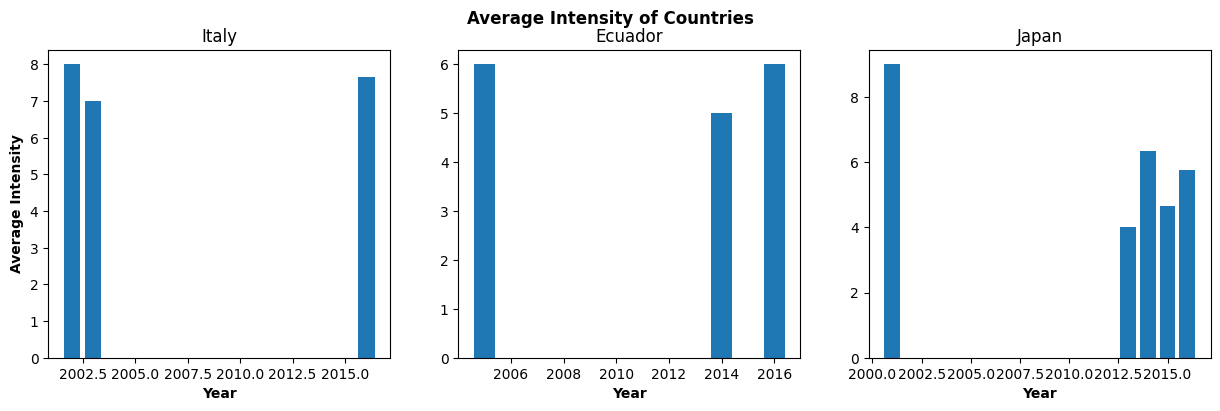

In [14]:
_nrows = 1
_ncols = 3
fig, ax = plt.subplots(nrows = 1, ncols = 3, figsize = (15, 4))

COUNTRIES = ["ITALY", "ECUADOR", "JAPAN"]

plt.suptitle(f"Average Intensity of Countries", fontweight = "bold")
for i, COUNTRY in enumerate(COUNTRIES):

    plt.subplot(_nrows, _ncols, i + 1)

    plt.title(COUNTRY.capitalize())
    dt_country = dt[dt.Country == COUNTRY]
    dt_country_filtered = dt_country.loc[:, ["Intensity", "Year"]].dropna()
    dt_country_filtered = dt_country_filtered[dt_country_filtered.Year > 2000]
    dt_country_filtered_mean = dt_country_filtered.groupby("Year").mean()
    years = [int(year) for year in dt_country_filtered_mean.index]
    intensity_means = dt_country_filtered_mean["Intensity"].to_numpy()

    if i == 0:
        plt.ylabel("Average Intensity", fontweight = "bold")
    plt.xlabel("Year", fontweight = "bold")

    plt.bar(years, intensity_means)

plt.show()

These figures show the average intensity of earthquakes in three countries: Italy, Ecuador, and Japan after the year 2000.

---

In [15]:
list(pd.notnull(dt.loc[:, 'Earthquake : Damage (in M$)'])).count(True)

511

In [16]:
list(pd.notnull(dt.loc[:, 'Earthquake : Injuries'])).count(True)

1244

In [17]:
dt_intensity = list(np.where(pd.notnull(dt.loc[:, "Intensity"]).values == True)[0])
dt.iloc[dt_intensity]
dt_intensity_filtered = dt.loc[dt_intensity, ["Country",
                                              "Intensity",
                                              "Earthquake : Injuries",
                                              "Earthquake : Deaths",
                                              "Earthquake : Damage (in M$)",
                                              "Year"]]
dt_intensity_filtered = dt_intensity_filtered.fillna(0)

In [18]:
dt_intensity_filtered

,Country,Intensity,Earthquake : Injuries,Earthquake : Deaths,Earthquake : Damage (in M$),Year
1,IRAN,8.0,0.0,50.0,0.0,1969
2,ITALY,7.0,4.0,0.0,0.0,1969
3,CHINA,7.0,0.0,0.0,0.0,1969
5,PERU,10.0,350.0,82.0,6.0,1970
6,CHILE,7.0,0.0,0.0,0.0,1972
...,...,...,...,...,...,...
6190,BANGLADESH,5.0,0.0,0.0,0.0,2010
6191,SERBIA,6.0,100.0,2.0,0.0,2010
6199,EL SALVADOR,7.0,0.0,1.0,0.0,2014
6201,CHILE,9.0,14.0,7.0,600.0,2015


In [20]:
countries = set(dt_intensity_filtered.Country)


In [21]:
years = set(dt_intensity_filtered.Year)


In [22]:
1969 in list(dt_intensity_filtered.groupby("Country").get_group("IRAN")["Year"])

True

In [23]:
dt_intensity_filtered_groupby_country = dt_intensity_filtered.groupby("Country")

years_countries = dict()

for country in countries:
    country_years = list(dt_intensity_filtered_groupby_country.get_group(country).Year)
    for year in years:
        if year not in years_countries:
            years_countries[year] = []
        if year in country_years:
            years_countries[year].append(country)

years_countries_sorted = sorted(years_countries.items(), key = lambda i: len(i[1]), reverse=True)

In [24]:
# {"A":1, "B":0, "C":10, "D":2, "E", 20}

# ("B":0)
# ("A":1)
# ("D":2)
# ("C":10)
# ("E":20)

In [25]:
dt_intensity_filtered_2016 = dt_intensity_filtered[dt_intensity_filtered.Year == 2016]

In [26]:
with open("/dt__intensity_filtered_2016.csv", mode="w") as f:
    f.write('"country","continent","year","value","injuries","deaths","damages","iso_alpha"\n')

In [28]:
countries_intensity = dict()

with open("/dt__intensity_filtered_2016.csv", mode="a+") as f:
    for group in dt_intensity_filtered_2016.groupby("Country"):
        country_name = group[0]
        average_intensity = np.average(group[1].Intensity.values)
        average_injuries = np.average(group[1]["Earthquake : Injuries"].values)
        average_deaths = np.average(group[1]["Earthquake : Deaths"].values)
        average_damages = np.average(group[1]["Earthquake : Damage (in M$)"].values)
        f.write(f'"{country_name}","{get_cn_continent(country_name)[1]}",2016,{average_intensity},{average_injuries},{average_deaths},{average_damages},"{get_cn_continent(country_name)[0]}"\n')

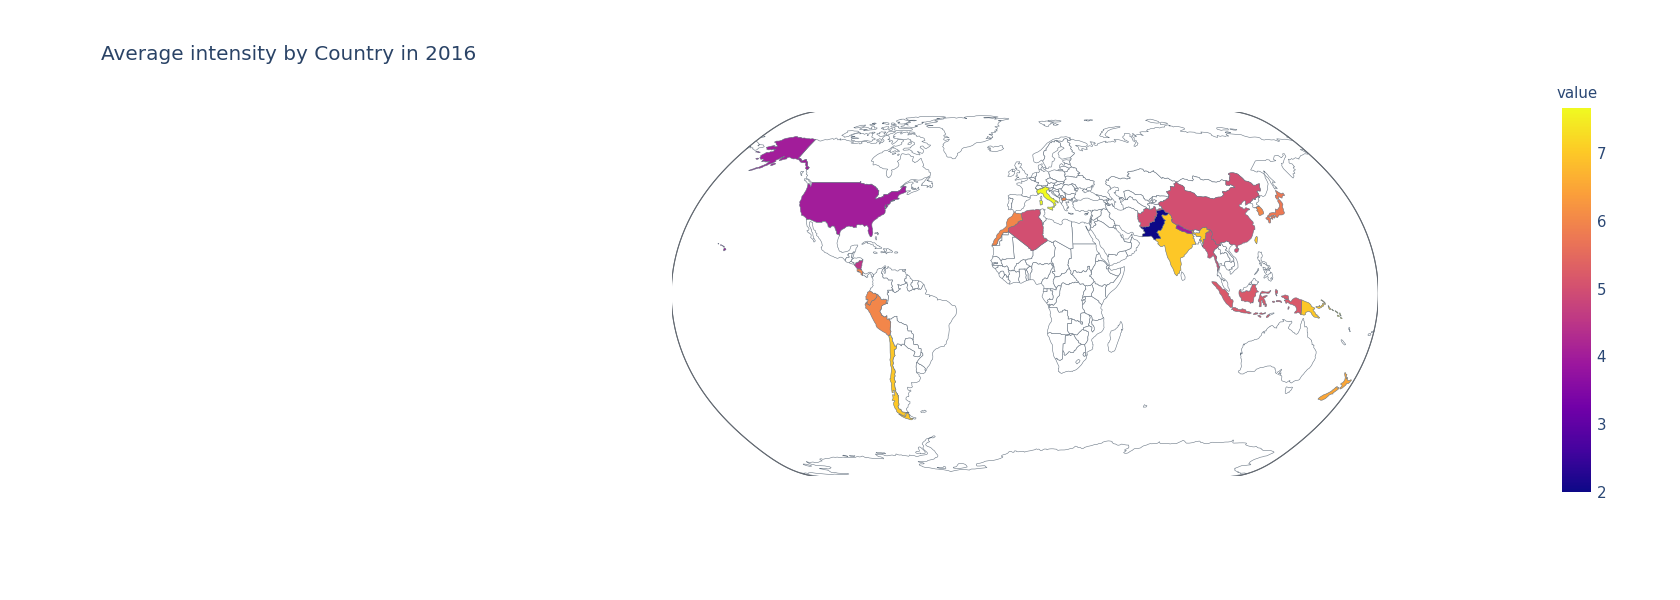

In [29]:
# Import data from GitHub
data = pd.read_csv('/dt__intensity_filtered_2016.csv')


# Create basic choropleth map
fig = px.choropleth(data, locations='iso_alpha', color='value', hover_name='country',
                    projection='natural earth', animation_frame='year',
                    title='Average intensity by Country in 2016')
fig.show()

The magnitudes of earthquakes varied across the countries, ranging from as low as 2.0 to as high as 7.67. This indicates a diverse seismic activity with different levels of intensity.Some countries experienced multiple earthquakes during the year. These regions may be considered seismic hotspots.Countries like Japan had earthquakes with an average magnitude of 5.75, while Italy had an average magnitude of approximately 7.67. This suggests differences in the seismic activity characteristics of these countries.Several countries experienced earthquakes with magnitudes considered significant, such as Chile (7.0), Italy (7.67), Papua New Guinea (7.0), Solomon Islands (7.5), and Taiwan (7.0).

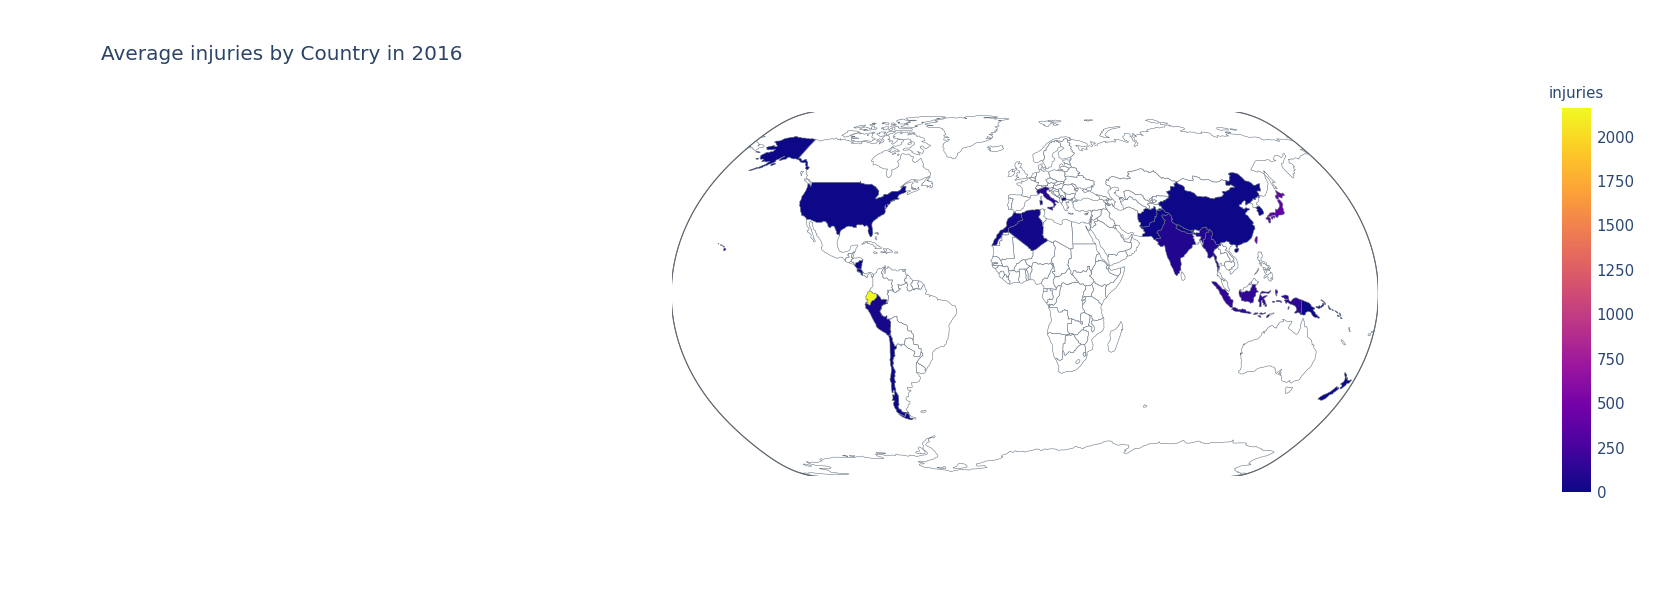

In [30]:
# Import data from GitHub
data = pd.read_csv('/dt__intensity_filtered_2016.csv')


# Create basic choropleth map
fig = px.choropleth(data, locations='iso_alpha', color='injuries', hover_name='country',
                    projection='natural earth', animation_frame='year',
                    title='Average injuries by Country in 2016')
fig.show()

This information provides insights into the varying degrees of impact earthquakes had on different countries in terms of reported injuries. Countries with higher reported injuries, such as Ecuador and Japan, may be more vulnerable to the impact of earthquakes, either due to population density, building infrastructure, or other factors.There is not a strict correlation between earthquake magnitudes and reported injuries. For instance, Taiwan reported a significant number of injuries despite not having the highest magnitude earthquake among the listed countries.

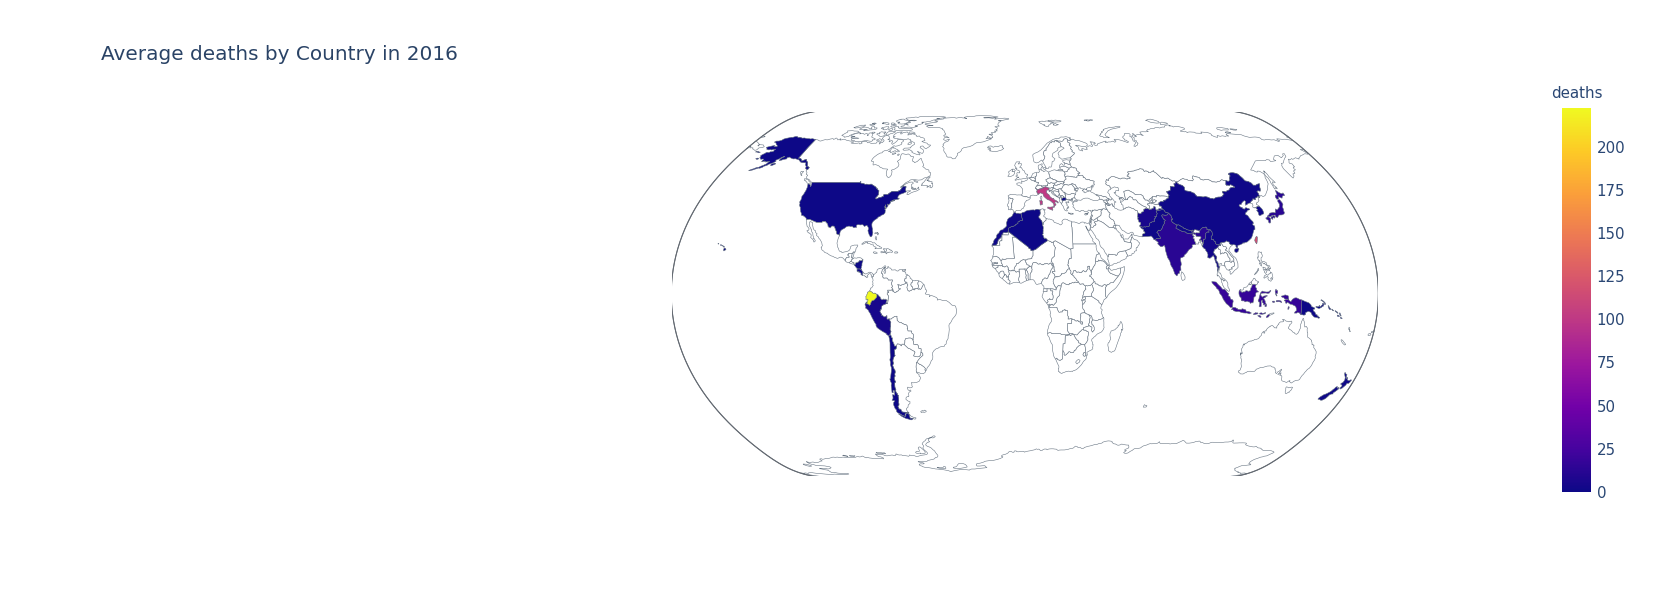

In [31]:
# Import data from GitHub
data = pd.read_csv('/dt__intensity_filtered_2016.csv')


# Create basic choropleth map
fig = px.choropleth(data, locations='iso_alpha', color='deaths', hover_name='country',
                    projection='natural earth', animation_frame='year',
                    title='Average deaths by Country in 2016')
fig.show()

The impact of earthquakes on human fatalities varies widely among countries. Some countries, like Ecuador, Italy, and Taiwan, reported substantial numbers of deaths, while others, such as Algeria, Chile, and the USA, reported no or minimal deaths.Countries with higher reported deaths, such as Ecuador and Italy, may be more vulnerable to the impact of earthquakes, either due to population density, building infrastructure, or other factors.There is not a strict correlation between earthquake magnitudes and reported deaths. For instance, Taiwan reported a significant number of deaths despite not having the highest magnitude earthquake among the listed countries.

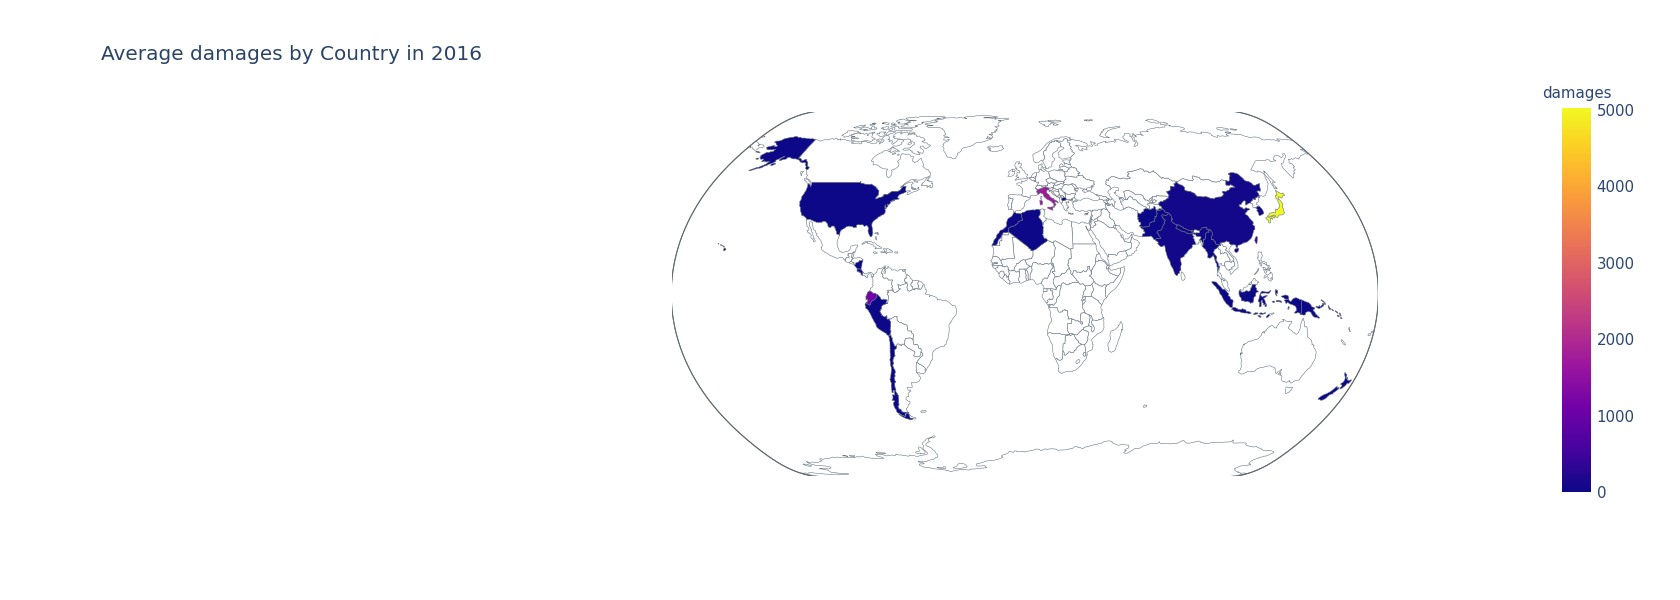

In [32]:
# Import data from GitHub
data = pd.read_csv('/dt__intensity_filtered_2016.csv')


# Create basic choropleth map
fig = px.choropleth(data, locations='iso_alpha', color='damages', hover_name='country',
                    projection='natural earth', animation_frame='year',
                    title='Average damages by Country in 2016')
fig.show()

Certain regions, such as earthquake-prone areas like Japan and Taiwan, reported higher damages, indicating the geographic vulnerability of these areas to seismic events.Some countries, including Nepal and New Zealand, reported damages despite not having the highest magnitude earthquakes among the listed countries. This emphasizes the localized impact of seismic events.